# `GeoCroissant`: Landslide4Sense (HDF5) 🥐

## Introduction

**Croissant 🥐** is an open format that describes machine learning datasets in a single JSON-LD file. It builds on schema.org to make datasets discoverable, interoperable, and reproducible across ML frameworks.

<img src="../assets/geocr.jpg" alt="GeoCroissant" width="115" style="float: right; margin-left: 24px; margin-top: 6px; margin-bottom: 12px; border-radius: 8px;">

**GeoCroissant** extends Croissant with first-class geospatial metadata:
* Coordinate reference systems (CRS)
* Spatial and temporal resolution
* Multi-sensor spectral band configurations and wavelengths
* Spatial coverage, sampling strategies, and geospatial bias documentation

<div style="clear: both;"></div>

In [1]:
import json
import os
from pathlib import Path

import h5py
from huggingface_hub import hf_hub_download
import matplotlib.pyplot as plt
import mlcroissant as mlc
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset

## 1. Landslide4Sense Dataset Overview

The [Landslide4Sense](https://huggingface.co/datasets/ibm-nasa-geospatial/Landslide4sense) dataset was introduced in the [2022 Landslide4Sense Competition](https://github.com/iarai/Landslide4Sense-2022) organized by the Institute of Advanced Research in Artificial Intelligence (IARAI) and published in *IEEE JSTARS* (Ghorbanzadeh et al., 2022).

It is a global benchmark dataset designed for large-scale landslide detection using multi-sensor satellite remote sensing imagery.

### Key Specifications:
* **Task:** Binary semantic segmentation (0: Non-landslide, 1: Landslide).
* **Patch Size:** 128 × 128 pixels labeled pixel-wise.
* **Spatial Resolution:** Resampled to ~10 meters per pixel across all bands.
* **Storage Format:** Hierarchical Data Format 5 (HDF5 / `.h5`).
  * Image files contain a dataset named `img` with shape `(128, 128, 14)` (`float64` / `float32`).
  * Mask files contain a dataset named `mask` with shape `(128, 128)` (`uint8`).
* **Splits:**
  * **Train:** 3,799 patches (`images/train/image_*.h5`, `annotations/train/mask_*.h5`)
  * **Validation:** 245 patches (`images/validation/image_*.h5`, `annotations/validation/mask_*.h5`)
  * **Test:** 800 patches (`images/test/image_*.h5`, `annotations/test/mask_*.h5`)
  * **Total:** 4,844 patches.

## 2. Define the GeoCroissant Metadata

In [ ]:
# 1. Define FileObject for the Hugging Face repository
repo = mlc.FileObject(
    id="landslide4sense-repo",
    name="landslide4sense-repo",
    description=(
        "Hugging Face dataset repository for ibm-nasa-geospatial/Landslide4sense"
        " containing HDF5 multi-sensor satellite imagery and annotations."
    ),
    content_url="https://huggingface.co/datasets/ibm-nasa-geospatial/Landslide4sense",
    encoding_formats=["git+https"],
    sha256="main",
)

# 2. FileSets define resource groups inside the repository
distribution = [
    repo,
    mlc.FileSet(
        id="train-images",
        name="train-images",
        description="Training satellite image patches (14 bands, HDF5 format)",
        contained_in=["landslide4sense-repo"],
        encoding_formats=["application/x-hdf5"],
        includes=["images/train/*.h5"],
    ),
    mlc.FileSet(
        id="train-masks",
        name="train-masks",
        description="Training binary landslide masks (HDF5 format)",
        contained_in=["landslide4sense-repo"],
        encoding_formats=["application/x-hdf5"],
        includes=["annotations/train/*.h5"],
    ),
    mlc.FileSet(
        id="valid-images",
        name="valid-images",
        description="Validation satellite image patches (14 bands, HDF5 format)",
        contained_in=["landslide4sense-repo"],
        encoding_formats=["application/x-hdf5"],
        includes=["images/validation/*.h5"],
    ),
    mlc.FileSet(
        id="valid-masks",
        name="valid-masks",
        description="Validation binary landslide masks (HDF5 format)",
        contained_in=["landslide4sense-repo"],
        encoding_formats=["application/x-hdf5"],
        includes=["annotations/validation/*.h5"],
    ),
    mlc.FileSet(
        id="test-images",
        name="test-images",
        description="Test satellite image patches (14 bands, HDF5 format)",
        contained_in=["landslide4sense-repo"],
        encoding_formats=["application/x-hdf5"],
        includes=["images/test/*.h5"],
    ),
    mlc.FileSet(
        id="test-masks",
        name="test-masks",
        description="Test binary landslide masks (HDF5 format)",
        contained_in=["landslide4sense-repo"],
        encoding_formats=["application/x-hdf5"],
        includes=["annotations/test/*.h5"],
    ),
]

band_names = [
    "B1",
    "B2",
    "B3",
    "B4",
    "B5",
    "B6",
    "B7",
    "B8",
    "B9",
    "B10",
    "B11",
    "B12",
    "Slope",
    "DEM",
]


# 3. Helper function to create RecordSets for each split
def create_split_record_sets(split_name, image_fileset, mask_fileset):
    return [
        mlc.RecordSet(
            id=f"{split_name}_images",
            name=f"{split_name} images",
            spatial_resolution=mlc.QuantitativeValue(value=10, unitText="m"),
            fields=[
                mlc.Field(
                    id=f"{split_name}/filename",
                    name="filename",
                    data_types=[mlc.DataType.TEXT],
                    source=mlc.Source(
                        file_set=image_fileset,
                        extract=mlc.Extract(file_property="filename"),
                    ),
                ),
                mlc.Field(
                    id=f"{split_name}/image",
                    name="image",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="128,128,14",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=14,
                        band_names_list=band_names,
                    ),
                    source=mlc.Source(
                        file_set=image_fileset,
                        extract=mlc.Extract(file_property="content"),
                    ),
                ),
            ],
        ),
        mlc.RecordSet(
            id=f"{split_name}_masks",
            name=f"{split_name} masks",
            fields=[
                mlc.Field(
                    id=f"{split_name}/mask_filename",
                    name="mask_filename",
                    data_types=[mlc.DataType.TEXT],
                    source=mlc.Source(
                        file_set=mask_fileset,
                        extract=mlc.Extract(file_property="filename"),
                    ),
                ),
                mlc.Field(
                    id=f"{split_name}/mask",
                    name="mask",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="128,128,1",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=1,
                        band_names_list=["mask"],
                    ),
                    source=mlc.Source(
                        file_set=mask_fileset,
                        extract=mlc.Extract(file_property="content"),
                    ),
                ),
            ],
        ),
        mlc.RecordSet(
            id=f"{split_name}_examples",
            name=f"{split_name} examples",
            fields=[
                mlc.Field(
                    id=f"{split_name}_examples/patch_id",
                    name="patch_id",
                    data_types=[mlc.DataType.TEXT],
                    source=mlc.Source(
                        field=f"{split_name}/filename",
                        transforms=[mlc.Transform(regex=r"^image_(\d+)\.h5$")],
                    ),
                    references=mlc.Source(
                        field=f"{split_name}/mask_filename",
                        transforms=[mlc.Transform(regex=r"^mask_(\d+)\.h5$")],
                    ),
                ),
                mlc.Field(
                    id=f"{split_name}_examples/image",
                    name="image",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="128,128,14",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=14,
                        band_names_list=band_names,
                    ),
                    source=mlc.Source(field=f"{split_name}/image"),
                ),
                mlc.Field(
                    id=f"{split_name}_examples/mask",
                    name="mask",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="128,128,1",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=1,
                        band_names_list=["mask"],
                    ),
                    source=mlc.Source(field=f"{split_name}/mask"),
                ),
            ],
        ),
    ]


record_sets = [
    *create_split_record_sets("train", "train-images", "train-masks"),
    *create_split_record_sets("valid", "valid-images", "valid-masks"),
    *create_split_record_sets("test", "test-images", "test-masks"),
]

# 4. Instantiate GeoCroissant Metadata
metadata = mlc.Metadata(
    name="landslide4sense",
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/RAI/",
        "http://mlcommons.org/croissant/geo/",
    ],
    description=(
        "Landslide4Sense is a global benchmark dataset for landslide detection from"
        " multi-sensor satellite imagery (Sentinel-2 multispectral and ALOS PALSAR"
        " slope and elevation data)."
    ),
    url="https://huggingface.co/datasets/ibm-nasa-geospatial/Landslide4sense",
    cite_as="""@article{L4S-2022,
  author={Ghorbanzadeh, Omid and Xu, Yonghao and Zhao, Hengwei and Wang, Junjue and Zhong, Yanfei and Zhao, Dong and Zang, Qi and Wang, Shuang and Zhang, Fahong and Shi, Yilei and Zhu, Xiao Xiang and Bai, Lin and Li, Weile and Peng, Weihang and Ghamisi, Pedram},
  journal={IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing},
  title={The Outcome of the 2022 Landslide4Sense Competition: Advanced Landslide Detection From Multisource Satellite Imagery},
  year={2022},
  volume={15},
  pages={9927-9942},
  doi={10.1109/JSTARS.2022.3220845}}""",
    date_published="2022-10-18",
    version="1.0.0",
    license="CC-BY-4.0",
    keywords=[
        "landslide4sense",
        "landslide detection",
        "remote sensing",
        "satellite imagery",
        "Sentinel-2",
        "ALOS PALSAR",
        "geospatial",
        "HDF5",
        "semantic segmentation",
    ],
    creators=[
        mlc.Person(name="Omid Ghorbanzadeh"),
        mlc.Person(name="Yonghao Xu"),
        mlc.Person(name="Pedram Ghamisi"),
    ],
    coordinate_reference_system="EPSG:4326",
    spatial_resolution=mlc.QuantitativeValue(value=10, unitText="m"),
    temporal_resolution=mlc.QuantitativeValue(value=1, unitText="years"),
    sampling_strategy=(
        "128x128 pixel patches centered on landslide events worldwide from 2015 to"
        " 2021, resampled to 10m resolution."
    ),
    spatial_bias=(
        "Globally distributed across mountainous, seismically active, and heavy"
        " rainfall regions (e.g., Japan and other landslide-prone zones)."
    ),
    band_configuration=mlc.BandConfiguration(
        total_bands=14,
        band_names_list=band_names,
    ),
    spectral_band_metadata=[
        mlc.SpectralBand(
            name="B1",
            center_wavelength=mlc.QuantitativeValue(value=443, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=20, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B2",
            center_wavelength=mlc.QuantitativeValue(value=490, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=65, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B3",
            center_wavelength=mlc.QuantitativeValue(value=560, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=35, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B4",
            center_wavelength=mlc.QuantitativeValue(value=665, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=30, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B5",
            center_wavelength=mlc.QuantitativeValue(value=705, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=15, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B6",
            center_wavelength=mlc.QuantitativeValue(value=740, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=15, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B7",
            center_wavelength=mlc.QuantitativeValue(value=783, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=20, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B8",
            center_wavelength=mlc.QuantitativeValue(value=842, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=115, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B9",
            center_wavelength=mlc.QuantitativeValue(value=945, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=20, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B10",
            center_wavelength=mlc.QuantitativeValue(value=1375, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=30, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B11",
            center_wavelength=mlc.QuantitativeValue(value=1610, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=90, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="B12",
            center_wavelength=mlc.QuantitativeValue(value=2190, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=180, unitText="nm"),
        ),
        mlc.SpectralBand(name="Slope"),
        mlc.SpectralBand(name="DEM"),
    ],
    spatial_coverage={
        "@type": "Place",
        "geo": {
            "@type": "GeoShape",
            "box": "-90.0 -180.0 90.0 180.0",
        },
    },
    distribution=distribution,
    record_sets=record_sets,
)

print("Metadata instantiated successfully")

Metadata instantiated successfully


In [3]:
# Serialize to JSON-LD
metadata_json = metadata.to_json()
metadata_json["@context"]["containedIn"] = "cr:containedIn"

output_json = "landslide4sense.json"
with open(output_json, "w") as f:
    json.dump(metadata_json, f, indent=2)

print(f"Metadata saved to {output_json}")

Metadata saved to landslide4sense.json


## 3. Validate the Metadata

We validate the generated `landslide4sense.json` using the `mlcroissant` command-line tool:

In [4]:
!mlcroissant validate --jsonld=landslide4sense.json

I1107 13:30:38.076834 137193347702784 validate.py:53] Done.


## 4. Load Dataset Metadata with `mlcroissant`

We can load and inspect the GeoCroissant dataset in Python:

In [5]:
dataset = mlc.Dataset(jsonld="landslide4sense.json")
meta = dataset.metadata

print(f"Dataset Name: {meta.name}")
print(f"Description:  {meta.description}")
print(f"Total Bands:  {meta.band_configuration.total_bands}")
print(f"Band Names:   {meta.band_configuration.band_names_list}")
print(
    f"Resolution:   {meta.spatial_resolution.value} {meta.spatial_resolution.unitText}"
)
print(f"CRS:          {meta.coordinate_reference_system}")
print(f"RecordSets:   {[rs.name for rs in meta.record_sets]}")

Dataset Name: landslide4sense


Description:  Landslide4Sense is a global benchmark dataset for landslide detection from multi-sensor satellite imagery (Sentinel-2 multispectral and ALOS PALSAR slope and elevation data).
Total Bands:  14
Band Names:   ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'Slope', 'DEM']
Resolution:   10 m
CRS:          EPSG:4326
RecordSets:   ['train images', 'train masks', 'train examples', 'valid images', 'valid masks', 'valid examples', 'test images', 'test masks', 'test examples']


## 5. Reproducible PyTorch Dataset & DataLoader

To ensure reproducibility across local machines, servers, and cloud environments:
1. The dataset loader accepts an optional `data_dir` pointing to local data if already downloaded.
2. If files are not present locally, it automatically downloads required patches via `huggingface_hub.hf_hub_download` (cached in the standard Hugging Face cache directory).
3. `Landslide4SenseDataset` reads the multi-band HDF5 `img` array and binary `mask` array, converting them to PyTorch tensors with shape `(channels, height, width)` suitable for deep learning segmentation models.

In [6]:
class Landslide4SenseDataset(Dataset):
    """PyTorch Dataset for Landslide4Sense HDF5 multi-sensor data."""

    def __init__(self, sample_ids, split="train", data_dir=None):
        self.sample_ids = sample_ids
        self.split = split
        self.data_dir = Path(data_dir) if data_dir else None

    def _get_file_path(self, subfolder: str, prefix: str, idx: int) -> str:
        filename = f"{prefix}_{idx}.h5"
        rel_path = f"{subfolder}/{self.split}/{filename}"

        # Check local path first
        if self.data_dir and (self.data_dir / rel_path).exists():
            return str(self.data_dir / rel_path)

        # Download or load from Hugging Face Hub cache
        return hf_hub_download(
            repo_id="ibm-nasa-geospatial/Landslide4sense",
            filename=rel_path,
            repo_type="dataset",
        )

    def __len__(self):
        return len(self.sample_ids)

    def __getitem__(self, index):
        sample_id = self.sample_ids[index]
        img_path = self._get_file_path("images", "image", sample_id)
        mask_path = self._get_file_path("annotations", "mask", sample_id)

        # Read HDF5 arrays
        with h5py.File(img_path, "r") as f:
            img = np.array(f["img"][:], dtype=np.float32)  # shape: (128, 128, 14)

        with h5py.File(mask_path, "r") as f:
            mask = np.array(f["mask"][:], dtype=np.int64)  # shape: (128, 128)

        # PyTorch expects channels-first format: (C, H, W)
        img_tensor = torch.from_numpy(img).permute(2, 0, 1)
        mask_tensor = torch.from_numpy(mask)

        return {
            "id": sample_id,
            "image": img_tensor,
            "mask": mask_tensor,
        }


# Verify DataLoader with the first 3 training samples
sample_ids = [1, 2, 3]
torch_dataset = Landslide4SenseDataset(sample_ids=sample_ids, split="train")
loader = DataLoader(torch_dataset, batch_size=1, shuffle=False)

records_list = []
print("Iterating over PyTorch DataLoader...")
for batch in loader:
    sample_id = batch["id"].item()
    img = batch["image"]
    mask = batch["mask"]
    landslide_pixels = (mask == 1).sum().item()
    total_pixels = mask.numel()

    print(f"Sample {sample_id}:")
    print(f"  Image shape: {img.shape} (Channels, Height, Width)")
    print(f"  Mask shape:  {mask.shape} (Height, Width)")
    print(
        f"  Landslide count: {landslide_pixels} / {total_pixels} pixels"
        f" ({landslide_pixels/total_pixels*100:.2f}%)"
    )

    records_list.append(batch)

Iterating over PyTorch DataLoader...


Sample 1:
  Image shape: torch.Size([1, 14, 128, 128]) (Channels, Height, Width)
  Mask shape:  torch.Size([1, 128, 128]) (Height, Width)
  Landslide count: 405 / 16384 pixels (2.47%)


Sample 2:
  Image shape: torch.Size([1, 14, 128, 128]) (Channels, Height, Width)
  Mask shape:  torch.Size([1, 128, 128]) (Height, Width)
  Landslide count: 937 / 16384 pixels (5.72%)


Sample 3:
  Image shape: torch.Size([1, 14, 128, 128]) (Channels, Height, Width)
  Mask shape:  torch.Size([1, 128, 128]) (Height, Width)
  Landslide count: 0 / 16384 pixels (0.00%)


## 6. Multi-Sensor & Landslide Mask Visualizations

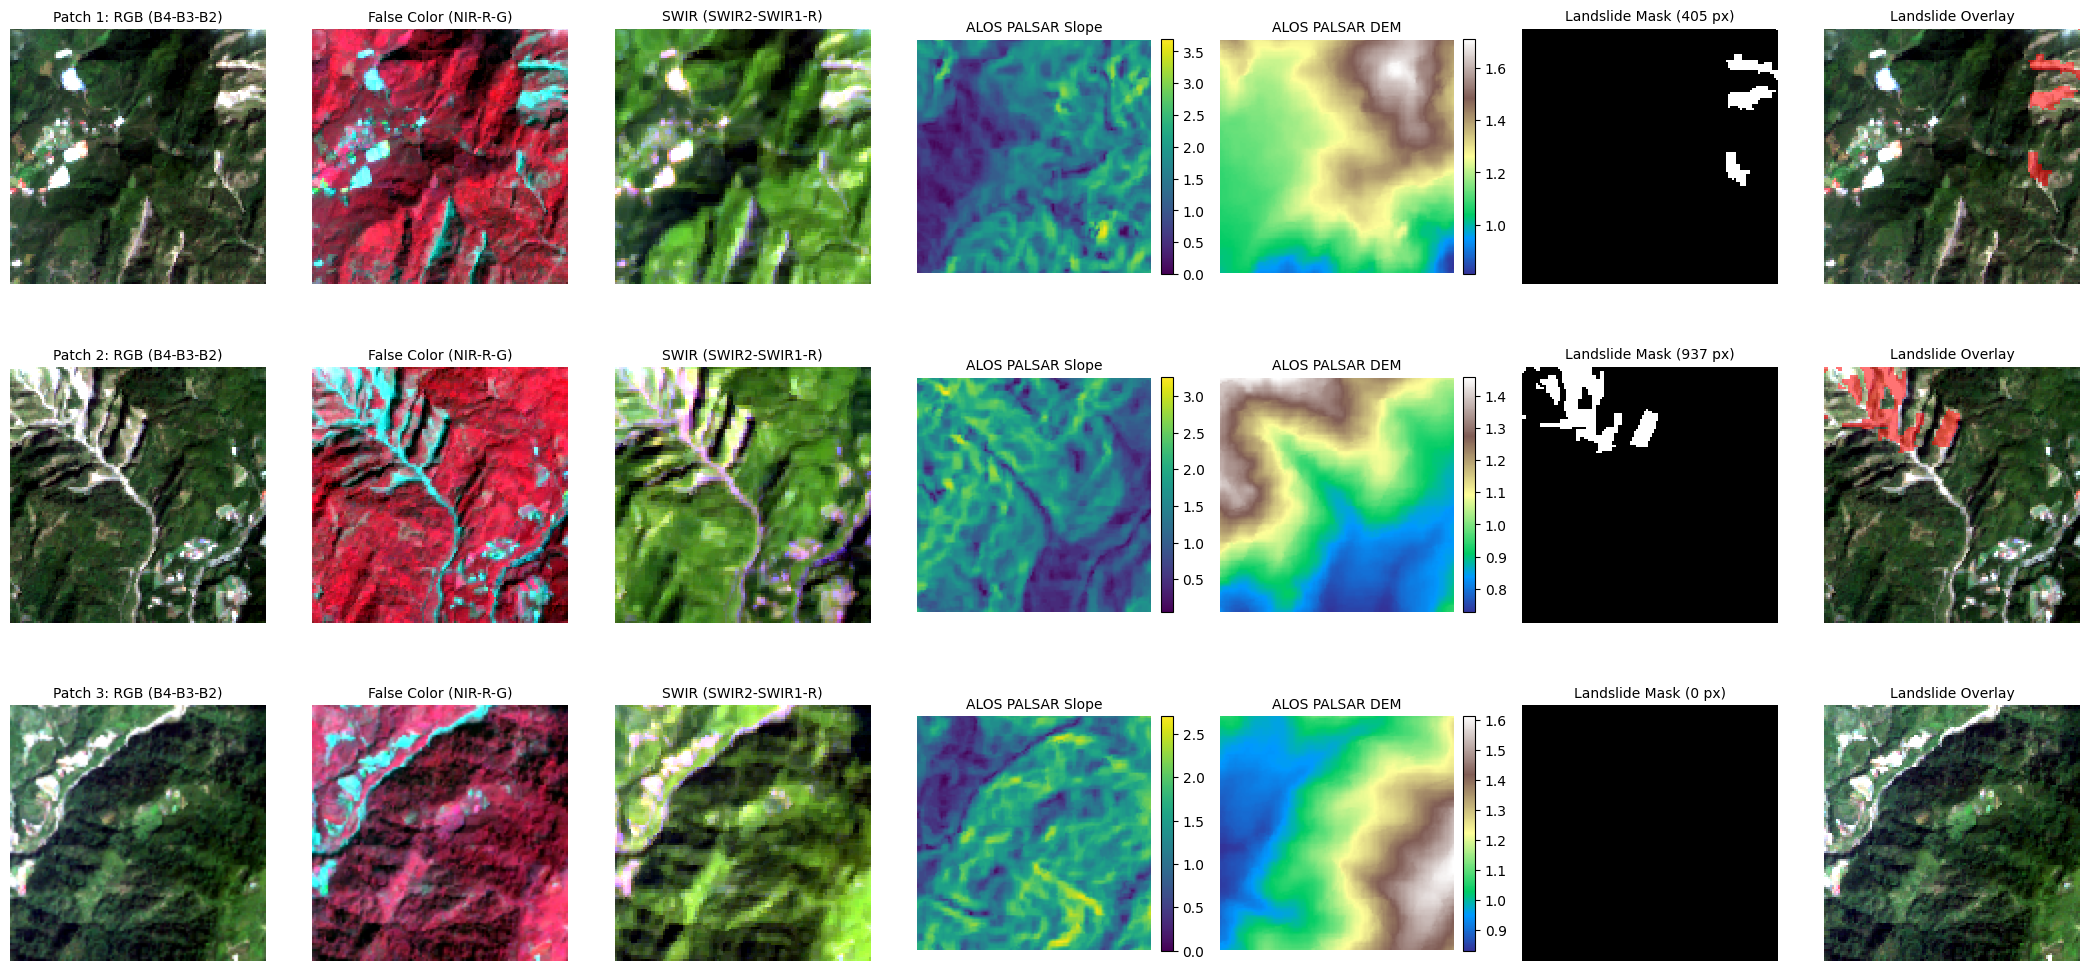

In [7]:
def normalize_rgb(band_stack):
    """Applies percentile clipping to 3-band array for clear visualization."""
    clipped = np.zeros_like(band_stack)
    for c in range(3):
        b = band_stack[:, :, c]
        p2, p98 = np.percentile(b, 2), np.percentile(b, 98)
        if p98 > p2:
            clipped[:, :, c] = np.clip((b - p2) / (p98 - p2), 0, 1)
        else:
            clipped[:, :, c] = np.clip(b, 0, 1)
    return clipped


num_samples = len(records_list)
fig, axes = plt.subplots(
    num_samples, 7, figsize=(21, 3.5 * num_samples), facecolor="white"
)

for row_idx, batch in enumerate(records_list):
    sample_id = batch["id"].item()
    img_tensor = batch["image"][0]  # shape: (14, 128, 128)
    mask_arr = batch["mask"][0].numpy()  # shape: (128, 128)

    # Convert tensor to (H, W, C) numpy array
    img_hwc = img_tensor.permute(1, 2, 0).numpy()

    # 1. RGB: Bands 4 (Red), 3 (Green), 2 (Blue) -> indices 3, 2, 1
    rgb_raw = img_hwc[:, :, [3, 2, 1]]
    rgb = normalize_rgb(rgb_raw)

    # 2. False Color NIR: Bands 8 (NIR), 4 (Red), 3 (Green) -> indices 7, 3, 2
    fc_raw = img_hwc[:, :, [7, 3, 2]]
    fc_nir = normalize_rgb(fc_raw)

    # 3. SWIR: Bands 12 (SWIR2), 11 (SWIR1), 4 (Red) -> indices 11, 10, 3
    swir_raw = img_hwc[:, :, [11, 10, 3]]
    swir = normalize_rgb(swir_raw)

    # 4. Slope: Band 13 -> index 12
    slope = img_hwc[:, :, 12]

    # 5. DEM: Band 14 -> index 13
    dem = img_hwc[:, :, 13]

    # Col 0: RGB
    axes[row_idx, 0].imshow(rgb)
    axes[row_idx, 0].set_title(f"Patch {sample_id}: RGB (B4-B3-B2)", fontsize=10)
    axes[row_idx, 0].axis("off")

    # Col 1: False Color NIR
    axes[row_idx, 1].imshow(fc_nir)
    axes[row_idx, 1].set_title("False Color (NIR-R-G)", fontsize=10)
    axes[row_idx, 1].axis("off")

    # Col 2: SWIR
    axes[row_idx, 2].imshow(swir)
    axes[row_idx, 2].set_title("SWIR (SWIR2-SWIR1-R)", fontsize=10)
    axes[row_idx, 2].axis("off")

    # Col 3: Slope
    im_slope = axes[row_idx, 3].imshow(slope, cmap="viridis")
    axes[row_idx, 3].set_title("ALOS PALSAR Slope", fontsize=10)
    axes[row_idx, 3].axis("off")
    plt.colorbar(im_slope, ax=axes[row_idx, 3], fraction=0.046, pad=0.04)

    # Col 4: DEM
    im_dem = axes[row_idx, 4].imshow(dem, cmap="terrain")
    axes[row_idx, 4].set_title("ALOS PALSAR DEM", fontsize=10)
    axes[row_idx, 4].axis("off")
    plt.colorbar(im_dem, ax=axes[row_idx, 4], fraction=0.046, pad=0.04)

    # Col 5: Landslide Mask
    axes[row_idx, 5].imshow(mask_arr, cmap="gray", vmin=0, vmax=1)
    landslide_count = (mask_arr == 1).sum()
    axes[row_idx, 5].set_title(f"Landslide Mask ({landslide_count} px)", fontsize=10)
    axes[row_idx, 5].axis("off")

    # Col 6: RGB with Landslide Overlay
    axes[row_idx, 6].imshow(rgb)
    overlay = np.zeros((*mask_arr.shape, 4))
    overlay[mask_arr == 1] = [1.0, 0.0, 0.0, 0.55]  # Translucent red overlay
    axes[row_idx, 6].imshow(overlay)
    axes[row_idx, 6].set_title("Landslide Overlay", fontsize=10)
    axes[row_idx, 6].axis("off")

plt.tight_layout()
plt.show()